## Foward/Backward Selection, PCR, and PLSR

### 1. Dependencies

In [1]:
from prep import *
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression

X_train, X_test, y_train, y_test, meta = load_model_data()
p = X_train.shape[1]
print(f"{p} lagged features, {len(X_train)} training quarters")

# sizes / component counts to try (kept below the number of features)
SIZES = [k for k in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20] if k < p]
COMPONENTS = [k for k in range(1, 16) if k <= p]

train 1992-03-31 to 2014-12-31  (92, 27)
test  2015-03-31 to 2025-12-31  (44, 27)
27 lagged features, 92 training quarters


### 2. Forward And Backward Selection
`SequentialFeatureSelector` picks features with its own inner time-series CV; the outer `tune()` picks **how many** features to keep.

In [2]:
def selection_pipe(direction):
    return make_pipeline(*preprocess(scale=True),
                         SequentialFeatureSelector(LinearRegression(), direction=direction,
                                                   scoring="neg_root_mean_squared_error",
                                                   cv=TimeSeriesSplit(n_splits=3)),
                         LinearRegression())

fwd_search = tune(selection_pipe("forward"),
                  {"sequentialfeatureselector__n_features_to_select": SIZES}, X_train, y_train)
bwd_search = tune(selection_pipe("backward"),
                  {"sequentialfeatureselector__n_features_to_select": SIZES}, X_train, y_train)
fwd_best, bwd_best = fwd_search.best_estimator_, bwd_search.best_estimator_

best params: {'sequentialfeatureselector__n_features_to_select': 2}
best CV root_mean_squared_error: 0.2267
best params: {'sequentialfeatureselector__n_features_to_select': 1}
best CV root_mean_squared_error: 0.2358


#### 1. Number of Total Best Features

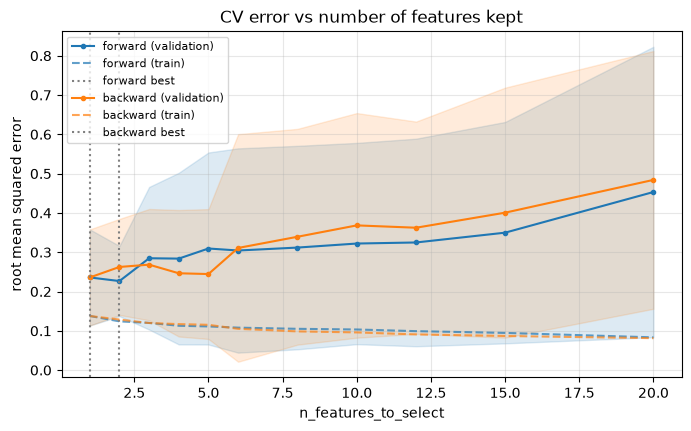

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_tuning(fwd_search, "sequentialfeatureselector__n_features_to_select", logx=False, ax=ax)
plot_tuning(bwd_search, "sequentialfeatureselector__n_features_to_select", logx=False, ax=ax)
ax.legend(ax.get_lines(), ["forward (validation)", "forward (train)", "forward best",
                           "backward (validation)", "backward (train)", "backward best"], fontsize=8)
ax.set_title("CV error vs number of features kept")
plt.show()

> **Note:** Train error (dashed) always falls as features are added; validation error stops improving (or rises) once extra features only fit noise. The best size is where validation error bottoms out.

#### 2. Choosen Best Features

In [4]:
def chosen(model):
    return list(X_train.columns[model.named_steps["sequentialfeatureselector"].get_support()])

fwd_feats, bwd_feats = chosen(fwd_best), chosen(bwd_best)
both = sorted(set(fwd_feats) & set(bwd_feats))
print(f"forward  ({len(fwd_feats)}): {fwd_feats}")
print(f"backward ({len(bwd_feats)}): {bwd_feats}")
print(f"chosen by both ({len(both)}): {both}")

forward  (2): ['dq_other_cons_L1', 'co_other_cons_L1']
backward (1): ['co_other_cons_L1']
chosen by both (1): ['co_other_cons_L1']


> **Note:** Features chosen by **both** directions are the most trustworthy. Disagreement usually means correlated features are interchangeable (e.g. `L1` vs `L2` of the same variable).

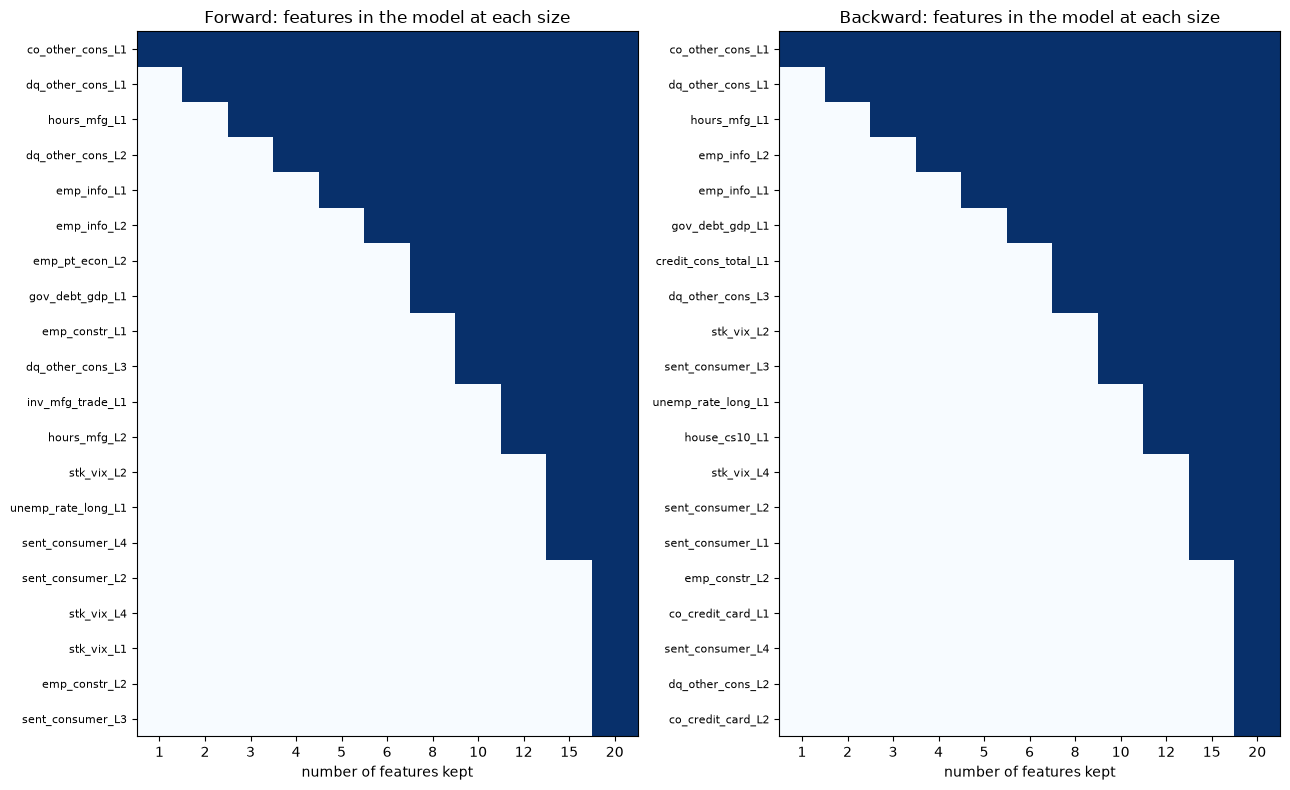

In [5]:
# selection path: which features are in the model at each size (fit on the training period)
def selection_path(direction, sizes):
    cols = {}
    for k in sizes:
        m = make_pipeline(*preprocess(scale=True),
                          SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction=direction,
                                                    scoring="neg_root_mean_squared_error",
                                                    cv=TimeSeriesSplit(n_splits=3))).fit(X_train, y_train)
        cols[k] = pd.Series(m[-1].get_support(), index=X_train.columns)
    return pd.DataFrame(cols)

def plot_selection_path(path, title, ax):
    order = path.sum(axis=1).sort_values(ascending=False)
    order = order[order > 0].index
    ax.imshow(path.loc[order].astype(int).values, cmap="Blues", aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(path.shape[1]), path.columns)
    ax.set_yticks(range(len(order)), order, fontsize=8)
    ax.set_xlabel("number of features kept")
    ax.set_title(title)

fwd_path = selection_path("forward", SIZES)
bwd_path = selection_path("backward", SIZES)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * max(fwd_path.sum(axis=1).gt(0).sum(), 8) + 2))
plot_selection_path(fwd_path, "Forward: features in the model at each size", axes[0])
plot_selection_path(bwd_path, "Backward: features in the model at each size", axes[1])
plt.tight_layout(); plt.show()

> **Note:** Blue = in the model. Features at the top are kept at almost every size (strongest). Forward shows the **order of entry**; backward shows the **order of removal** (read right to left).

#### 3. Weights, Stability, and Scores

<Axes: title={'center': 'Backward selection: coefficients (others dropped)'}>

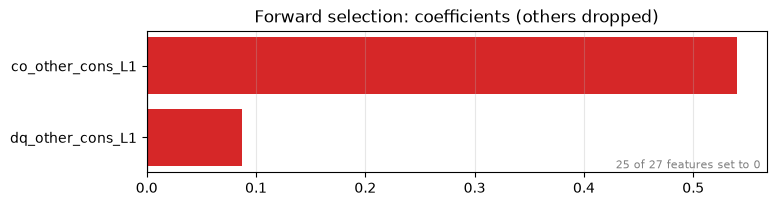

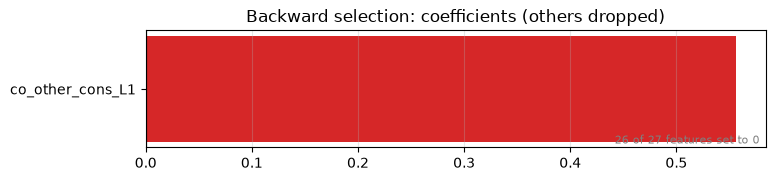

In [6]:
plot_feature_weights(fwd_best, X_train, top=len(fwd_feats), title="Forward selection: coefficients (others dropped)")
plot_feature_weights(bwd_best, X_train, top=len(bwd_feats), title="Backward selection: coefficients (others dropped)")

In [7]:
# does selection pick the same features in every time fold? (share of folds used = 1.0 -> always chosen)
W_fwd, stab_fwd = weight_stability(fwd_best, X_train, y_train)
stab_fwd[stab_fwd["share of folds used"] > 0].round(3)

,full-training weight,mean across folds,sd across folds,share of folds used,sign flips
feature,,,,,
co_other_cons_L1,0.540,0.287,0.162,1.0,False
dq_other_cons_L1,0.087,0.036,0.039,0.6,False
house_cs10_L1,0.000,0.011,0.025,0.2,False
sent_consumer_L2,0.000,0.013,0.028,0.2,False


> **Note:** Low "share of folds used" or sign flips mean the selection depends on which years are in the data: a classic weakness of stepwise selection with correlated predictors, and a good point for the Overfitting section.

In [8]:
display(score(fwd_best, X_train, X_test, y_train, y_test))
score(bwd_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.192,0.116,0.896,0.685,92.0
model - test,0.089,0.065,0.878,0.659,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.084,0.060,0.841,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.210,0.129,0.875,0.467,92.0
model - test,0.103,0.063,0.836,0.636,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.081,0.053,0.853,0.694,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


<Axes: title={'center': 'Test-period forecasts by model'}, ylabel='co_other_cons'>

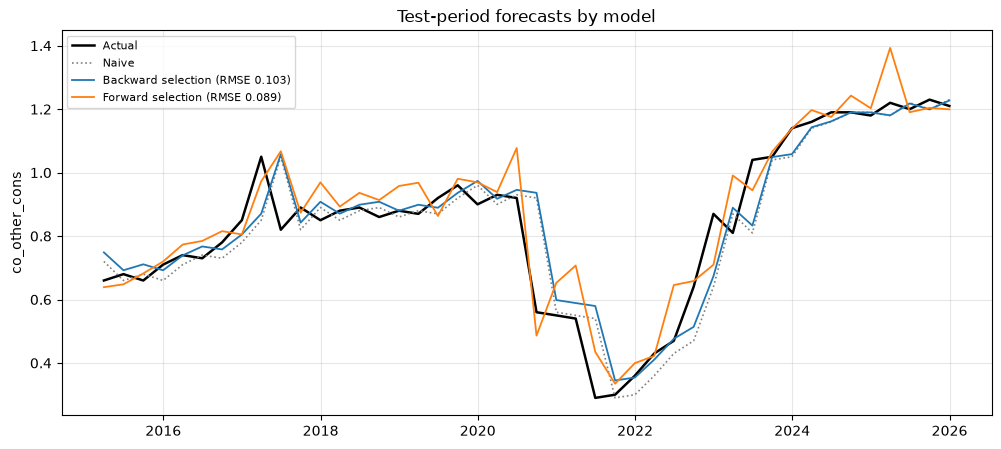

In [9]:
plot_forecasts(names=['Forward selection','Backward selection'])

In [10]:
record("Forward selection", fwd_best, X_train, X_test, y_train, y_test, search=fwd_search,
       notes=f"{len(fwd_feats)} features: {fwd_feats}")
record("Backward selection", bwd_best, X_train, X_test, y_train, y_test, search=bwd_search,
       notes=f"{len(bwd_feats)} features: {bwd_feats}")

recorded 'Forward selection' -> /workspaces/DX799-O1/model_data/results
recorded 'Backward selection' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.210,0.129,0.875,0.467,92.0
model - test,0.103,0.063,0.836,0.636,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.081,0.053,0.853,0.694,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 3. PCR: Principal Component Regression

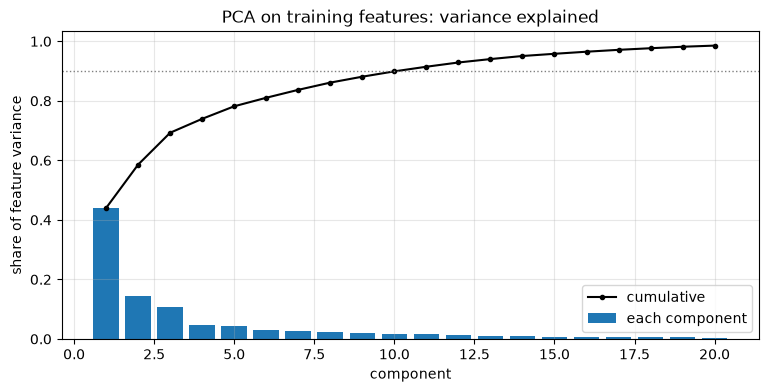

components for 90% of variance: 11


In [11]:
# how much of the variation in the (scaled) features each component captures, on the training period
pca_full = make_pipeline(*preprocess(scale=True), PCA()).fit(X_train)[-1]
ev = pd.Series(pca_full.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(len(pca_full.explained_variance_ratio_))])

fig, ax = plt.subplots(figsize=(9, 4))
n_show = min(20, len(ev))
ax.bar(range(1, n_show + 1), ev.values[:n_show], label="each component")
ax.plot(range(1, n_show + 1), ev.cumsum().values[:n_show], color="black", marker="o", ms=3, label="cumulative")
ax.axhline(0.9, color="grey", ls=":", lw=1)
ax.set_xlabel("component"); ax.set_ylabel("share of feature variance")
ax.set_title("PCA on training features: variance explained")
ax.legend(); ax.grid(alpha=0.3); plt.show()
print(f"components for 90% of variance: {int((ev.cumsum() < 0.9).sum()) + 1}")

In [12]:
pcr_pipe = make_pipeline(*preprocess(scale=True), PCA(), LinearRegression())
pcr_search = tune(pcr_pipe, {"pca__n_components": COMPONENTS}, X_train, y_train)
pcr_best = pcr_search.best_estimator_
pcr_k = pcr_search.best_params_["pca__n_components"]

best params: {'pca__n_components': 4}
best CV root_mean_squared_error: 0.3644


<Axes: title={'center': 'Tuning: n_components'}, xlabel='n_components', ylabel='root mean squared error'>

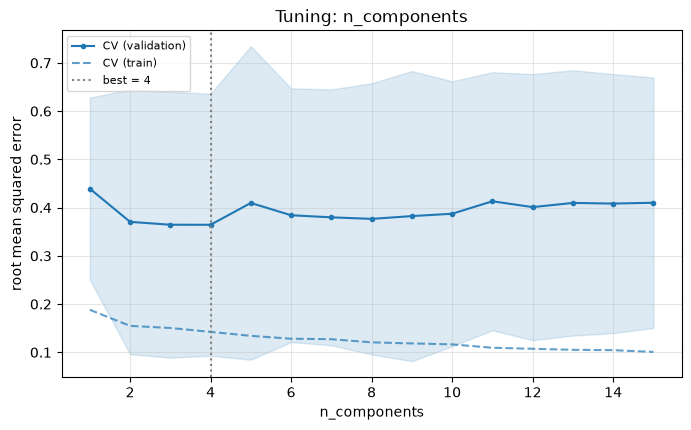

In [13]:
plot_tuning(pcr_search, "pca__n_components", logx=False)

#### 1. Components makeup

In [14]:
# loadings: how strongly each original feature contributes to the first components
pca_fit = pcr_best.named_steps["pca"]
loadings = pd.DataFrame(pca_fit.components_.T, index=X_train.columns,
                        columns=[f"PC{i+1}" for i in range(pca_fit.n_components_)])
for pc in loadings.columns[:min(3, pca_fit.n_components_)]:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(8)
    print(f"\n{pc} ({pca_fit.explained_variance_ratio_[int(pc[2:]) - 1]:.0%} of variance) - largest loadings:")
    print(top.round(3).to_string())


PC1 (44% of variance) - largest loadings:
emp_constr_L1         0.266
emp_constr_L2         0.265
co_other_cons_L1     -0.261
unemp_rate_long_L1   -0.231
inv_mfg_trade_L1      0.228
co_credit_card_L1    -0.221
emp_info_L1           0.217
gov_debt_gdp_L1      -0.211

PC2 (15% of variance) - largest loadings:
sent_consumer_L4    0.380
sent_consumer_L3    0.363
sent_consumer_L2    0.343
sent_consumer_L1    0.323
stk_vix_L1          0.252
stk_vix_L2          0.251
hours_mfg_L1       -0.234
stk_vix_L3          0.216

PC3 (11% of variance) - largest loadings:
house_cs10_L1        0.388
stk_vix_L4           0.355
co_credit_card_L2    0.351
dq_other_cons_L1    -0.333
dq_other_cons_L2    -0.332
co_credit_card_L1    0.281
emp_pt_econ_L1      -0.238
stk_vix_L3           0.235


> **Note:** Name each component from its largest loadings (e.g. a component loading on unemployment, claims and spreads at several lags is a "labor-market stress" factor). Lags of the same variable usually load together, which is how PCR handles correlated lags.

<Axes: title={'center': 'PCR (4 components): implied weight per feature'}>

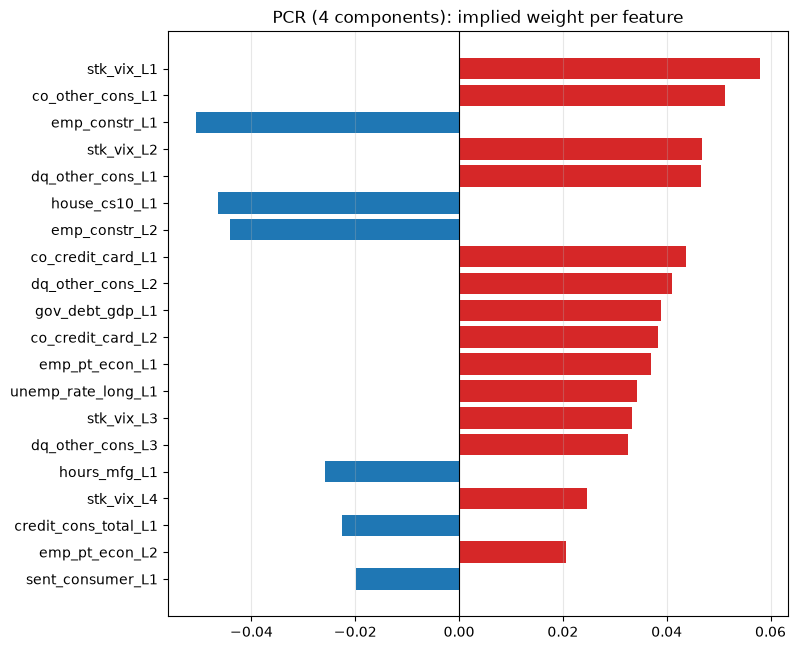

In [15]:
# PCR coefficients mapped back to the original features
plot_feature_weights(pcr_best, X_train, top=20, title=f"PCR ({pcr_k} components): implied weight per feature")

In [16]:
score(pcr_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.258,0.190,0.812,0.543,92.0
model - test,0.460,0.242,-2.273,0.591,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.206,0.152,0.047,0.639,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


In [17]:
record("PCR", pcr_best, X_train, X_test, y_train, y_test, search=pcr_search,
       notes=f"{pcr_k} components ({pca_full.explained_variance_ratio_[:pcr_k].sum():.0%} of feature variance)")

recorded 'PCR' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.258,0.190,0.812,0.543,92.0
model - test,0.460,0.242,-2.273,0.591,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.206,0.152,0.047,0.639,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 4. PLSR

In [18]:
pls_pipe = make_pipeline(*preprocess(scale=True), PLSRegression(scale=False))
pls_search = tune(pls_pipe, {"plsregression__n_components": [k for k in COMPONENTS if k <= 10]}, X_train, y_train)
pls_best = pls_search.best_estimator_
pls_k = pls_search.best_params_["plsregression__n_components"]

best params: {'plsregression__n_components': 2}
best CV root_mean_squared_error: 0.3892


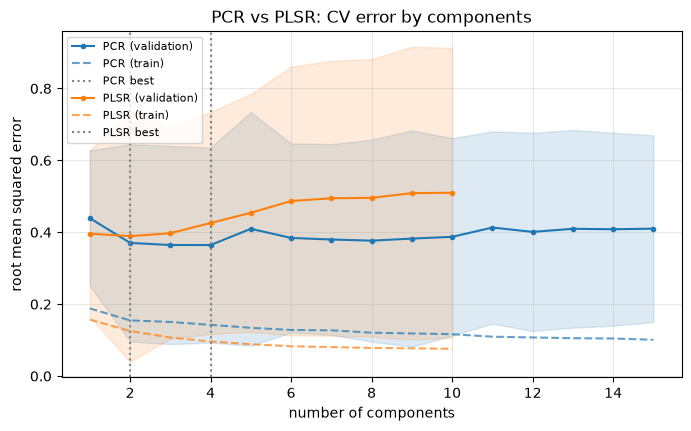

In [19]:
# PCR vs PLSR: CV error by number of components on one chart
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_tuning(pcr_search, "pca__n_components", logx=False, ax=ax)
plot_tuning(pls_search, "plsregression__n_components", logx=False, ax=ax)
ax.legend(ax.get_lines(), ["PCR (validation)", "PCR (train)", "PCR best",
                           "PLSR (validation)", "PLSR (train)", "PLSR best"], fontsize=8)
ax.set_xlabel("number of components"); ax.set_title("PCR vs PLSR: CV error by components")
plt.show()

> **Note:** PLSR builds components that track the target, so it typically reaches its best error with fewer components than PCR. If PCR needs many components, the main directions of variation in the macro data are not the ones that drive charge-offs.

In [20]:
pls_fit = pls_best.named_steps["plsregression"]
pls_load = pd.DataFrame(pls_fit.x_loadings_, index=X_train.columns,
                        columns=[f"PLS{i+1}" for i in range(pls_fit.n_components)])
for c in pls_load.columns[:min(2, pls_fit.n_components)]:
    print(f"\n{c} - largest loadings:")
    print(pls_load[c].reindex(pls_load[c].abs().sort_values(ascending=False).index).head(8).round(3).to_string())


PLS1 - largest loadings:
emp_constr_L1        -0.269
emp_constr_L2        -0.265
co_other_cons_L1      0.265
unemp_rate_long_L1    0.234
inv_mfg_trade_L1     -0.230
co_credit_card_L1     0.222
emp_info_L1          -0.214
hours_mfg_L2         -0.214

PLS2 - largest loadings:
sent_consumer_L4    0.449
dq_other_cons_L1    0.438
sent_consumer_L3    0.433
dq_other_cons_L2    0.398
sent_consumer_L2    0.389
sent_consumer_L1    0.322
stk_vix_L1          0.283
emp_info_L2         0.270


<Axes: title={'center': 'PLSR (2 components): weight per feature'}>

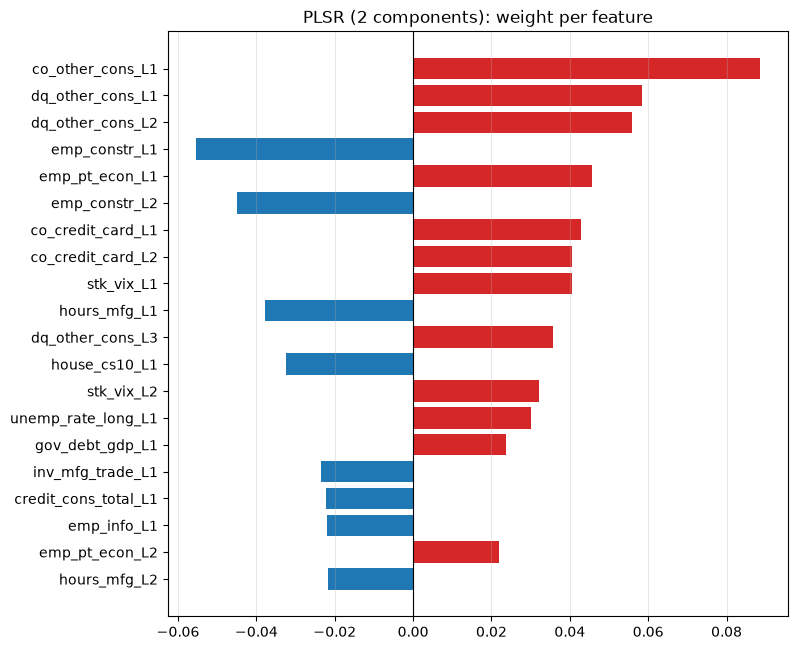

In [21]:
plot_feature_weights(pls_best, X_train, top=20, title=f"PLSR ({pls_k} components): weight per feature")

In [22]:
score(pls_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.237,0.181,0.841,0.641,92.0
model - test,0.453,0.200,-2.168,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.139,0.114,0.567,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


In [23]:
record("PLSR", pls_best, X_train, X_test, y_train, y_test, search=pls_search,
       notes=f"{pls_k} components")

recorded 'PLSR' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.237,0.181,0.841,0.641,92.0
model - test,0.453,0.200,-2.168,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.139,0.114,0.567,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 5. Compare Four Methods

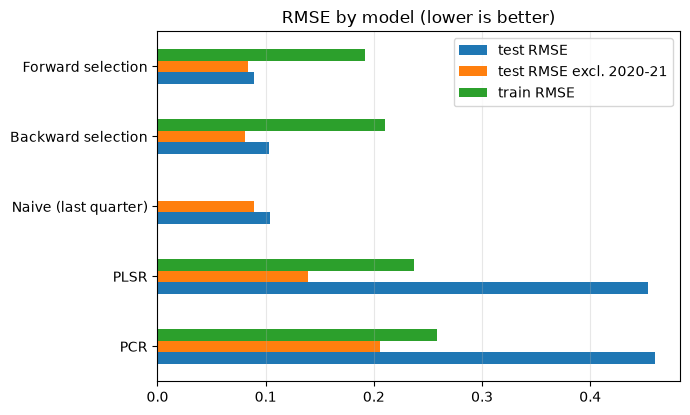

,type,test RMSE,test MAE,test R2,test DirAcc,test RMSE excl. 2020-21,train RMSE,overfit gap (test - train RMSE),CV score,CV metric,best params,saved
Forward selection,regressor,0.089,0.065,0.878,0.659,0.084,0.192,-0.103,0.22666,root_mean_squared_error,{'sequentialfeatureselector__n_features_to_sel...,2026-10-18 03:17
Backward selection,regressor,0.103,0.063,0.836,0.636,0.081,0.21,-0.107,0.235818,root_mean_squared_error,{'sequentialfeatureselector__n_features_to_sel...,2026-10-18 03:17
Naive (last quarter),baseline,0.104,0.066,0.832,NaN,0.089,NaN,NaN,NaN,NaN,NaN,NaN
PLSR,regressor,0.453,0.2,-2.168,0.614,0.139,0.237,0.216,0.389209,root_mean_squared_error,{'plsregression__n_components': 2},2026-10-18 03:22
PCR,regressor,0.46,0.242,-2.273,0.591,0.206,0.258,0.202,0.36442,root_mean_squared_error,{'pca__n_components': 4},2026-10-18 03:19


In [24]:
nb3 = ["Forward selection", "Backward selection", "PCR", "PLSR"]
compare(results={k: v for k, v in load_results().items() if k in nb3})

<Axes: title={'center': 'Test-period forecasts by model'}, ylabel='co_other_cons'>

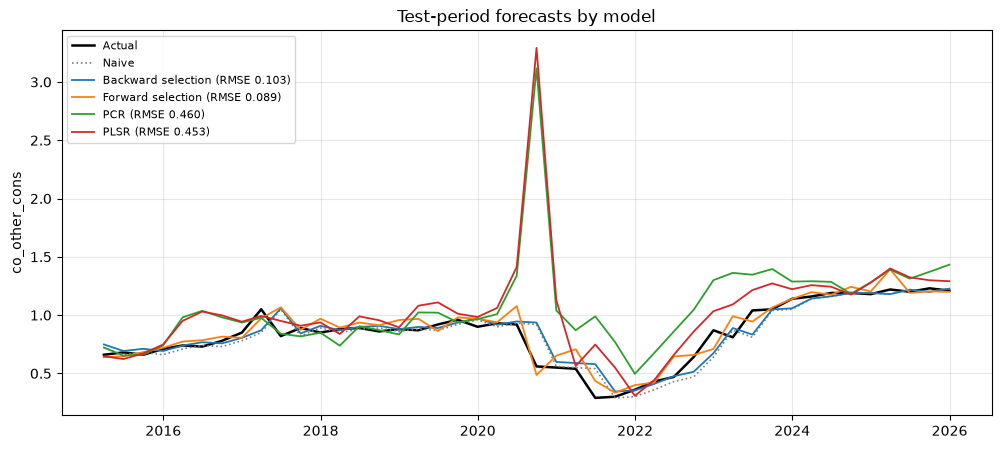

In [25]:
plot_forecasts(names=nb3)

best on test RMSE: Forward selection


<Axes: title={'center': 'Permutation importance (big train, small test = likely overfit)'}, xlabel='drop in root_mean_squared_error when shuffled'>

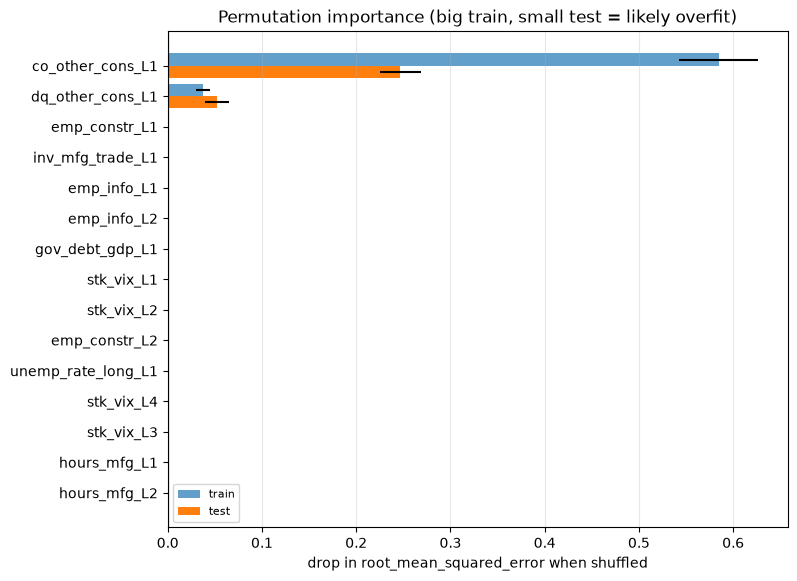

In [26]:
# overfitting check on the best of the four (train vs test permutation importance)
models3 = {"Forward selection": fwd_best, "Backward selection": bwd_best, "PCR": pcr_best, "PLSR": pls_best}
best3 = min(nb3, key=lambda k: load_results()[k]["metrics"].loc["model - test", "RMSE"])
print("best on test RMSE:", best3)
plot_permutation(permutation_table(models3[best3], X_train, y_train, X_test, y_test, n_repeats=20), top=15)

In [27]:
for k, m in models3.items():
    export_predictions(m, X_train, X_test, y_train, y_test, name=k)
pd.concat({"forward": fwd_path, "backward": bwd_path}, axis=1).to_csv(f"{EXPORT_DIR}/nb3_selection_paths.csv")
loadings.to_csv(f"{EXPORT_DIR}/nb3_pcr_loadings.csv")

saved 136 rows -> /workspaces/DX799-O1/model_data/exports/Forward_selection_predictions.csv
saved 136 rows -> /workspaces/DX799-O1/model_data/exports/Backward_selection_predictions.csv
saved 136 rows -> /workspaces/DX799-O1/model_data/exports/PCR_predictions.csv
saved 136 rows -> /workspaces/DX799-O1/model_data/exports/PLSR_predictions.csv


### 6. Notes

**Goal:** two different ways to deal with having many correlated lagged features and few quarters.

| Method | Idea | What you learn |
|---|---|---|
| **Forward selection** | start with no features, add the one that improves CV error most, repeat | which few features matter most, in order |
| **Backward selection** | start with all features, remove the least useful, repeat | which features can be dropped without hurting |
| **PCR** (principal component regression) | compress all features into a few uncorrelated **components** (directions of largest variation in X), then regress on those | whether a few broad "macro factors" explain charge-offs |
| **PLSR** (partial least squares) | like PCR, but components are built to be **related to the target**, not just to vary a lot | usually needs fewer components than PCR |

**Selection** keeps original features (easy to explain) but can be unstable with correlated lags. **PCR/PLSR** keep all features but blend them, which handles correlated lags well (lags of one variable tend to load on the same component) but is harder to explain.

Every method uses time-ordered cross-validation (`TimeSeriesSplit`), including the inner loop that picks features, so no future data is used to choose anything.

- **Selection:** best number of features (forward vs backward), which features both directions agree on, and how stable the choice is across time folds (stepwise selection is known to be unstable with correlated predictors).
- **PCR vs PLSR:** components needed, share of feature variance captured, and what the main components represent (name them from their loadings).
- **Lags:** selection picks specific lags (e.g. `dq_other_cons_L1` but not L2), while PCR/PLSR blend lags of the same variable into one component.
- **Overfitting:** train (dashed) vs validation curves as features/components are added; train–test gap in `compare()`; permutation train vs test.